Two-feature linear dataset:
$$
y = 3x_1 - 2x_2 + 4 + \epsilon
$$
where:
- $x_1,x_2 \sim \mathcal{N}(0,1)$
- $\epsilon \sim \mathcal{N}(0,0.2^2)$
- Number of samples: 200
- Random seed: 47
- Training/test split: 160/40

In [1]:
import numpy as np
rng = np.random.default_rng(seed=47)

n = 200
X = rng.normal(0, 1, size=(n, 2))

true_w = np.array([3.0, -2.0])
true_b = 4.0
noise = rng.normal(0, 0.2, size=n)

y = X @ true_w + true_b + noise

Convert NumPy -> Torch

In [2]:
import torch

torch.manual_seed(47)
X = torch.tensor(X, dtype=torch.float32)
true_w = torch.tensor(true_w, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)


Graph

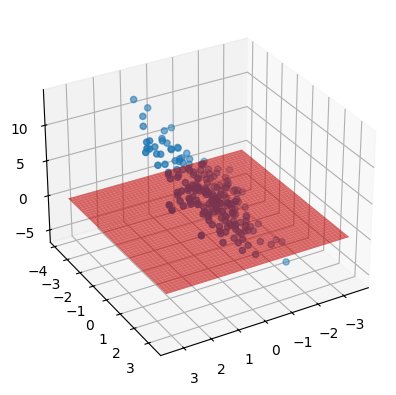

In [16]:
import matplotlib.pyplot as plt

def plot(w, b):
    fig = plt.figure()
    ax = plt.axes(projection='3d')
    ax.view_init(elev=30, azim=60, roll=0)

    ax.scatter(X[:, 0], X[:, 1], y.reshape(-1))

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    x1_grid, x2_grid = np.meshgrid(np.linspace(x1_min, x1_max, 50), 
                                   np.linspace(x2_min, x2_max, 50))

    grid_points = np.c_[x1_grid.ravel(), x2_grid.ravel()]
    Z = (grid_points @ w + b).reshape(x1_grid.shape)

    surface = ax.plot_surface(x1_grid, x2_grid, Z, color='red', alpha=0.6, edgecolor='none')

    plt.show()

plot(np.array([0.0, 0.0]), 0.0)

Pipeline:
1. Design model (input, output size, forward pass)
2. Construct loss and optimizer
3. Training loop:
    - Forward pass
    - Backward pass
    - Update weight

In [13]:
# VERY IMPORTANT CONVENTION:
# [batch_size, features]

print(y.shape)
y = y.reshape(-1, 1)
print(y.shape)

torch.Size([200])
torch.Size([200, 1])


Epoch: 0
MSE Loss: 28.973072052001953
---
Epoch: 20
MSE Loss: 0.6030796766281128
---
Epoch: 40
MSE Loss: 0.04496007412672043
---
Epoch: 60
MSE Loss: 0.03346424922347069
---
Epoch: 80
MSE Loss: 0.0332186296582222
---
Epoch: 100
MSE Loss: 0.033213235437870026
---
Epoch: 120
MSE Loss: 0.03321311995387077
---
Epoch: 140
MSE Loss: 0.03321311995387077
---
Epoch: 160
MSE Loss: 0.033213116228580475
---
Epoch: 180
MSE Loss: 0.033213116228580475
---
Parameter containing:
tensor([[ 3.0118, -2.0060]], requires_grad=True)
Parameter containing:
tensor([3.9856], requires_grad=True)


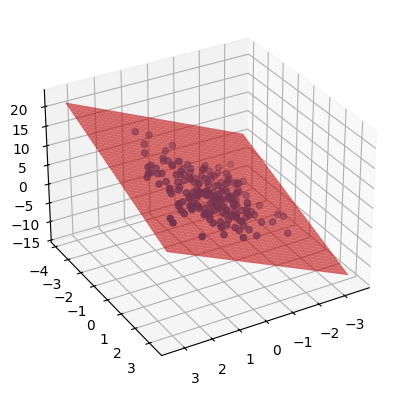

In [22]:
import torch.nn as nn

input_size = X.shape[1]
output_size = 1

# model = nn.Linear(in_features=input_size, out_features=output_size, bias=True)

# Try custom model:
class LinearRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LinearRegression, self).__init__()

        # Define layers
        self.lin = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.lin(x)

model = LinearRegression(input_dim=input_size, output_dim=output_size)

lr = 0.05
n_iters=200
loss = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

for epoch in range(n_iters):
    # y_pred = X @ w + b
    y_pred = model(X)

    # l = ((y_pred - y)**2).mean()
    l = loss(y_pred, y)

    l.backward()

    # with torch.no_grad():
    #     w -= w.grad*gd_lr 
    #     b -= b.grad*gd_lr
    optimizer.step()

    # w.grad.zero_()
    optimizer.zero_grad()

    if epoch % 20 == 0:
        print(f"Epoch: {epoch}")
        print(f"MSE Loss: {l}")
        print("---")

[w, b] = model.parameters()
print(w)
print(b)
plot(w.detach().numpy().reshape(-1), b.detach().numpy().reshape(-1))
        